# Notebook 09: Leakage Audit of Notebooks 02-07

## Purpose

Notebooks 02 to 07 have two leakage problems that make my reported results look better than they are. This notebook measures how much, and produces the numbers I will use from now on.

## Research question

How much of the PR-AUC and the threshold results in notebooks 04-07 (13/21 and 19/21 failures caught, 52 and 183 false alarms) comes from leakage and how much from real predictive signal?

## The two issues

1. Preprocessing leakage. In notebook 02 the zero-variance filter, the >50% missingness filter and the median imputer were fit on all 1,567 wafers before the split. Notebook 07 reused that data for cross-validation with only the scaler inside the pipeline, so held-out folds influenced which features were kept and how values were imputed.
2. Threshold leakage. In notebooks 04 and 06 I chose the thresholds (RF 0.20, XGB 0.35) by sweeping on the test set, so the catches and false alarms at those thresholds are optimistic.

## Scope

I do not modify notebooks 02-08 or the manuscript. Notebook 08 has the same preprocessing leak and is not re-run here.

## Prediction

I did not write down a prediction before running this notebook, so there is nothing to score against the results. The summary at the bottom says what I found.


## Step 1. Setup and load the raw data

I start from the raw files, not from X_train.csv and X_test.csv, because those were created after the leaky preprocessing. The asserts confirm this is the same dataset as notebooks 01-08: 1,567 wafers, 590 features, 104 failures.


In [2]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

import xgboost as xgb
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

DATA_RAW  = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES   = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 42

X = pd.read_csv(DATA_RAW / "secom.data", sep=r"\s+", header=None, engine="python")
y_raw = pd.read_csv(DATA_RAW / "secom_labels.data", sep=r"\s+", header=None,
                    usecols=[0], names=["label"], engine="python")["label"]
y = (y_raw == 1).astype(int)   # SECOM: -1 = pass, 1 = fail

assert X.shape == (1567, 590), X.shape
assert len(y) == 1567 and int(y.sum()) == 104, (len(y), int(y.sum()))
print(f"X: {X.shape} | failures: {int(y.sum())} ({y.mean()*100:.2f}%)")
print(f"Total missing values: {int(X.isna().sum().sum())}")

X: (1567, 590) | failures: 104 (6.64%)
Total missing values: 41951


## Step 2. Transformers that learn from training data only

sklearn has no built-in step for "drop columns that are constant in the training data" or "drop columns that are mostly missing in the training data". I wrote both as transformers. fit decides which columns to keep using only the data it is given, and transform applies that fixed choice to any data. Inside a Pipeline, cross_validate refits both filters on each training fold and only applies them to the held-out fold.

I copy the notebook 02 rules exactly: variance uses ddof=1, a column whose variance is NaN is kept, and a column is dropped when its missing rate is strictly greater than 0.5.


In [3]:
class ZeroVarianceFilter(BaseEstimator, TransformerMixin):
    """Drop columns whose variance is exactly 0 in the data it is fit on."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        var = pd.DataFrame(X).var(axis=0, ddof=1).to_numpy()
        self.keep_mask_ = ~(var == 0)          # matches notebook 02
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError(f"Expected {self.n_features_in_} columns, got {X.shape[1]}")
        return X[:, self.keep_mask_]


class MissingnessFilter(BaseEstimator, TransformerMixin):
    """Drop columns whose missing rate is > threshold in the data it is fit on."""
    def __init__(self, threshold=0.5):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.missing_rate_ = np.isnan(X).mean(axis=0)
        self.keep_mask_ = ~(self.missing_rate_ > self.threshold)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError(f"Expected {self.n_features_in_} columns, got {X.shape[1]}")
        return X[:, self.keep_mask_]

## Step 3. Check the transformers against notebook 02

If my transformers differ from notebook 02 in any way, the whole audit is meaningless, so I test them first.

1. Fit on all 1,567 wafers, they must reproduce the notebook 02 counts: 590 to 474 to 446.
2. Fit on one fold's training rows and applied to that fold's held-out rows, the number of columns must match.

If the first check fails I stop and debug before going further.


In [4]:
zv_all = ZeroVarianceFilter().fit(X)
X_zv = zv_all.transform(X)
ms_all = MissingnessFilter(0.5).fit(X_zv)
X_ms = ms_all.transform(X_zv)
print(f"Global fit -> after zero-variance: {X_zv.shape[1]} | after missingness: {X_ms.shape[1]}")
assert X_zv.shape[1] == 474 and X_ms.shape[1] == 446, "Does not reproduce notebook 02 counts"

skf_demo = StratifiedKFold(5, shuffle=True, random_state=SEED)
tr_idx, ho_idx = next(skf_demo.split(X, y))
zv = ZeroVarianceFilter().fit(X.iloc[tr_idx])
ms = MissingnessFilter(0.5).fit(zv.transform(X.iloc[tr_idx]))
A = ms.transform(zv.transform(X.iloc[tr_idx]))
B = ms.transform(zv.transform(X.iloc[ho_idx]))
print(f"Fold-1 train cols: {A.shape[1]} | held-out cols: {B.shape[1]}")
assert A.shape[1] == B.shape[1]

Global fit -> after zero-variance: 474 | after missingness: 446
Fold-1 train cols: 440 | held-out cols: 440


## Step 4. Models and pipelines

I use the same hyperparameters as notebook 07, so any change in the results comes from fixing the leakage and not from different settings.

There is one more small leak to close. In notebooks 06 and 07, scale_pos_weight came from the class ratio of the whole dataset (1463/104 = 14.07), which lets information about the held-out rows into the model. FoldWeightedXGB recomputes it from the training rows each time it is fit. On the 80% training split the ratio is 1170/83 = 14.10.

Pipeline order: zero-variance filter, missingness filter (0.5), median imputer, scaler, model.


In [5]:
class FoldWeightedXGB(xgb.XGBClassifier):
    """XGBClassifier that sets scale_pos_weight from the labels it is fit on."""
    def fit(self, X, y, **kwargs):
        y_arr = np.asarray(y)
        self.set_params(scale_pos_weight=float((y_arr == 0).sum() / (y_arr == 1).sum()))
        return super().fit(X, y_arr, **kwargs)


def make_clf(name):
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=2,
                                      class_weight="balanced", max_features="sqrt",
                                      random_state=SEED, n_jobs=-1)
    if name == "XGBoost":
        return FoldWeightedXGB(n_estimators=200, max_depth=4, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1,
                               reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbosity=0)
    raise ValueError(name)


def make_audited_pipeline(name):
    return Pipeline([("zv", ZeroVarianceFilter()),
                     ("miss", MissingnessFilter(0.5)),
                     ("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("clf", make_clf(name))])

MODELS = ["Random Forest", "XGBoost"]
print(make_audited_pipeline("XGBoost"))
print(f"Full-data neg/pos: {(y==0).sum()/(y==1).sum():.2f}")

Pipeline(steps=[('zv', ZeroVarianceFilter()), ('miss', MissingnessFilter()),
                ('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler()),
                ('clf',
                 FoldWeightedXGB(base_score=None, booster=None, callbacks=None,
                                 colsample_bylevel=None, colsample_bynode=None,
                                 colsample_bytree=0.8, device=None,
                                 early_stopping_rounds=None,
                                 enable_categorical=False, eval_metr...
                                 feature_types=None, feature_weights=None,
                                 gamma=None, grow_policy=None,
                                 importance_type=None,
                                 interaction_constraints=None,
                                 learning_rate=0.05, max_bin=None,
                                 max_cat_threshold=None, max_cat_to_onehot=None,
                           

## Part 1. Leakage-free 5-fold cross-validation

This is the corrected version of the notebook 07 CV. Every fold fits the filters, imputer, scaler and model on its own training rows and is scored on its untouched held-out rows. The metric is PR-AUC because only about 6.6% of wafers are failures.

What I look at in the output:

- the per-fold feature counts, and how far they are from the global 474 to 446
- the gap between the train score and the held-out score
- mean and standard deviation for each model


In [6]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_clean = {}
for name in MODELS:
    res = cross_validate(make_audited_pipeline(name), X, y, cv=cv5,
                         scoring="average_precision", return_train_score=True,
                         return_estimator=True, n_jobs=1)
    cv_clean[name] = res
    s = res["test_score"]
    print(f"{name:14s} PR-AUC {s.mean():.4f} ± {s.std():.4f} | folds {np.round(s, 4)} | "
          f"train {res['train_score'].mean():.4f}")

rows = []
for i, est in enumerate(cv_clean["Random Forest"]["estimator"], 1):
    rows.append({"fold": i,
                 "after_zero_var": int(est.named_steps["zv"].keep_mask_.sum()),
                 "after_missingness": int(est.named_steps["miss"].keep_mask_.sum())})
fold_features = pd.DataFrame(rows)
print(fold_features.to_string(index=False))
print("Global (notebook 02): 474 -> 446")

Random Forest  PR-AUC 0.1850 ± 0.0287 | folds [0.2207 0.1764 0.1444 0.169  0.2145] | train 1.0000
XGBoost        PR-AUC 0.1913 ± 0.0139 | folds [0.1883 0.2155 0.1747 0.1956 0.1823] | train 1.0000
 fold  after_zero_var  after_missingness
    1             468                440
    2             474                446
    3             474                446
    4             474                446
    5             474                450
Global (notebook 02): 474 -> 446


## Part 1b. How much did the preprocessing leak change the score?

Comparing the audited CV with the 0.1956 from notebook 07 mixes three things together: the leak itself, different fold assignments (notebook 07 used the concatenated train+test row order, so its folds are different), and the scale_pos_weight fix. To isolate the preprocessing leak I re-run the leaky version (filters and imputer fit on all rows, only the scaler in the pipeline) on the same raw-order data with the same folds. The per-fold differences are then paired, so fold difficulty cancels out.

A negative mean difference (audited minus leaky) means the leak was inflating the score. If the standard deviation is about as large as the mean, the difference is within noise.


Leaky global preprocessing on raw row order: (1567, 446)
Random Forest  (leaky, same folds) PR-AUC 0.1883 ± 0.0319
XGBoost        (leaky, same folds) PR-AUC 0.1884 ± 0.0212
Random Forest  audited - leaky per fold: [-0.0118 -0.0031  0.0002 -0.0004 -0.0013] | mean -0.0033 ± 0.0044
XGBoost        audited - leaky per fold: [-0.0258  0.0069  0.0183  0.0085  0.0063] | mean +0.0028 ± 0.0149


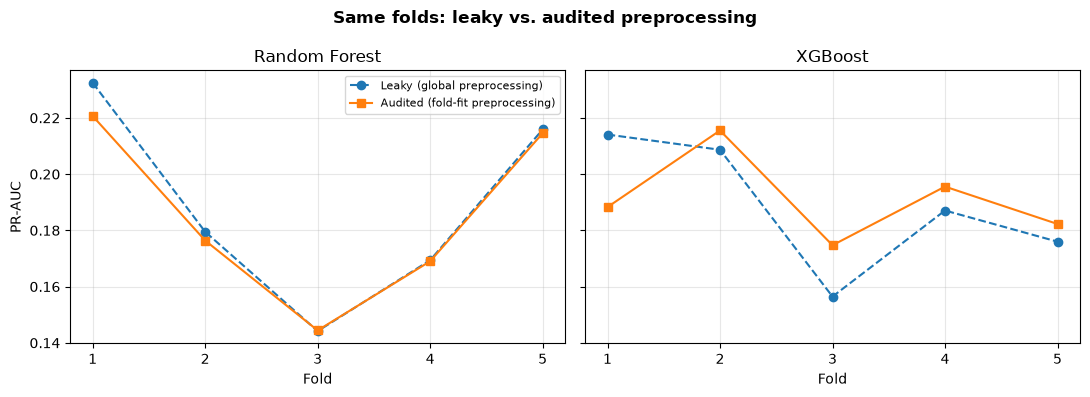

In [7]:
def global_preprocess(X_df):
    var = X_df.var(axis=0)
    X1 = X_df.loc[:, ~(var == 0)]
    X2 = X1.loc[:, ~(X1.isna().mean() > 0.5)]
    imp = SimpleImputer(strategy="median")
    return pd.DataFrame(imp.fit_transform(X2), columns=X2.columns)

X_leaky = global_preprocess(X)
print(f"Leaky global preprocessing on raw row order: {X_leaky.shape}")

def make_leaky_pipeline(name):
    return Pipeline([("scale", StandardScaler()), ("clf", make_clf(name))])

cv_leaky = {}
for name in MODELS:
    res = cross_validate(make_leaky_pipeline(name), X_leaky, y, cv=cv5,
                         scoring="average_precision", n_jobs=1)
    cv_leaky[name] = res
    s = res["test_score"]
    print(f"{name:14s} (leaky, same folds) PR-AUC {s.mean():.4f} ± {s.std():.4f}")

paired = {}
for name in MODELS:
    d = cv_clean[name]["test_score"] - cv_leaky[name]["test_score"]
    paired[name] = d
    print(f"{name:14s} audited - leaky per fold: {np.round(d, 4)} | mean {d.mean():+.4f} ± {d.std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, MODELS):
    folds = np.arange(1, 6)
    ax.plot(folds, cv_leaky[name]["test_score"], "o--", label="Leaky (global preprocessing)")
    ax.plot(folds, cv_clean[name]["test_score"], "s-", label="Audited (fold-fit preprocessing)")
    ax.set_title(name); ax.set_xlabel("Fold"); ax.set_xticks(folds); ax.grid(alpha=0.3)
axes[0].set_ylabel("PR-AUC"); axes[0].legend(fontsize=8)
plt.suptitle("Same folds: leaky vs. audited preprocessing", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "leakage_audit_cv_paired.png", dpi=150, bbox_inches="tight")
plt.show()

### Part 1 interpretation

1. The filters change slightly from fold to fold. Fold 1 kept 468 columns after the zero-variance filter and 440 after the missingness filter. Folds 2 to 4 kept 474 and 446, the same as the global fit. Fold 5 kept 474 and 450. Columns close to the 50% missingness cut-off flip in or out depending on which wafers are in the training fold.
2. Audited CV PR-AUC is 0.1850 ± 0.0287 for Random Forest and 0.1913 ± 0.0139 for XGBoost. Both models score 1.0000 on their own training folds, so the gap between train and held-out is very large.
3. The paired audited-minus-leaky difference is -0.0033 ± 0.0044 for RF and +0.0028 ± 0.0149 for XGB. Both are smaller than the fold-to-fold noise, and XGB's difference changes sign across folds (from -0.0258 to +0.0183). So the preprocessing leak had no detectable effect on CV PR-AUC here.
4. The notebook 07 numbers are not comparable to the audited numbers for three reasons. First, the preprocessing leak itself, which turned out to be small. Second, notebook 07 built its folds from concat(train, test), so its folds contain different wafers than mine. Third, notebook 07 computed scale_pos_weight on all 1,567 wafers instead of on each fold's training rows. The leaky comparator in this notebook already uses the per-fold weight, so the paired comparison isolates only the preprocessing leak. I cannot separate the fold effect from the weight effect.


## Part 2. Choosing the threshold without the test set

A threshold is a model parameter, so it has to be chosen without looking at the test set. The procedure:

1. Recreate the notebook 02 split (80/20, stratified, random_state=42). It must give 314 test wafers with 21 failures, and 83 failures among the 1,253 training wafers.
2. Using the training set only, get out-of-fold predicted probabilities with cross_val_predict. The filters and imputer are refit inside every fold.
3. Pick the threshold that maximises F1 on those out-of-fold predictions.
4. Fit the final pipeline on the whole training set and apply that fixed threshold to the test set once.

Max F1 treats a missed failure and a false alarm as equally costly, which is probably not true in a real fab. I use it because it is simple and needs no cost data, and I note this in the limitations.


In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
assert X_tr.shape == (1253, 590) and X_te.shape == (314, 590)
assert int(y_te.sum()) == 21 and int(y_tr.sum()) == 83
print(f"Train {X_tr.shape}, failures {int(y_tr.sum())} | Test {X_te.shape}, failures {int(y_te.sum())}")
print(f"Train neg/pos: {(y_tr==0).sum()/(y_tr==1).sum():.2f}")

# Cross-check against the files saved by notebook 02 (same rows, same order?)
try:
    saved_y = pd.read_csv(PROCESSED / "y_test.csv").squeeze().to_numpy()
    print("Label order matches notebook 02 y_test.csv:", np.array_equal(saved_y, y_te.to_numpy()))
    saved_X = pd.read_csv(PROCESSED / "X_test.csv")
    complete = [c for c in saved_X.columns if X[int(c)].isna().sum() == 0][:5]
    ok = all(np.allclose(saved_X[c].to_numpy(), X_te[int(c)].to_numpy()) for c in complete)
    print(f"Feature rows match notebook 02 X_test.csv on {len(complete)} complete columns:", ok)
except Exception as e:
    print(f"Cross-check with notebook 02 files skipped ({type(e).__name__}: {e})")

Train (1253, 590), failures 83 | Test (314, 590), failures 21
Train neg/pos: 14.10
Label order matches notebook 02 y_test.csv: True
Feature rows match notebook 02 X_test.csv on 5 complete columns: True


In [9]:
def best_f1_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    p, r = p[:-1], r[:-1]                      # thresholds has len(p) - 1
    f1 = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
    i = int(np.argmax(f1))
    return float(t[i]), float(f1[i])

cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof, THRESH = {}, {}
for name in MODELS:
    oof[name] = cross_val_predict(make_audited_pipeline(name), X_tr, y_tr, cv=cv_inner,
                                  method="predict_proba", n_jobs=1)[:, 1]
    THRESH[name], f1_oof = best_f1_threshold(y_tr, oof[name])
    print(f"{name:14s} OOF PR-AUC {average_precision_score(y_tr, oof[name]):.4f} | "
          f"threshold {THRESH[name]:.4f} | OOF F1 {f1_oof:.3f}")

with open(PROCESSED / "audit_thresholds.json", "w") as f:
    json.dump(THRESH, f, indent=2)

Random Forest  OOF PR-AUC 0.1647 | threshold 0.2802 | OOF F1 0.269
XGBoost        OOF PR-AUC 0.1537 | threshold 0.1404 | OOF F1 0.262


## Applying the frozen threshold to the test set once

The thresholds are now saved in audit_thresholds.json and will not change. I fit each final pipeline on the whole training set and score the test set one time. I report the threshold, failures caught out of 21, false alarms, alert rate, test PR-AUC and a 95% Clopper-Pearson interval on recall. With only 21 test failures, a difference like 13/21 versus 10/21 is three wafers, and the interval shows how little that tells me.


In [10]:
def clopper_pearson(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return float(lo), float(hi)

def evaluate_at(thr, proba, y_true):
    pred = proba >= thr
    caught = int((pred & (y_true.to_numpy() == 1)).sum())
    false_alarms = int((pred & (y_true.to_numpy() == 0)).sum())
    n_pos = int(y_true.sum())
    lo, hi = clopper_pearson(caught, n_pos)
    return {"threshold": round(float(thr), 4), "caught": caught, "n_failures": n_pos,
            "false_alarms": false_alarms, "alerts": int(pred.sum()),
            "alert_rate": round(float(pred.mean()), 3),
            "recall": round(caught / n_pos, 3), "recall_CI95": f"[{lo:.2f}, {hi:.2f}]"}

final_models, proba_te, audited = {}, {}, {}
for name in MODELS:
    final_models[name] = make_audited_pipeline(name).fit(X_tr, y_tr)
    proba_te[name] = final_models[name].predict_proba(X_te)[:, 1]
    row = evaluate_at(THRESH[name], proba_te[name], y_te)
    row["test_PR_AUC"] = round(average_precision_score(y_te, proba_te[name]), 4)
    audited[name] = row
    print(name, row)

Random Forest {'threshold': 0.2802, 'caught': 4, 'n_failures': 21, 'false_alarms': 14, 'alerts': 18, 'alert_rate': 0.057, 'recall': 0.19, 'recall_CI95': '[0.05, 0.42]', 'test_PR_AUC': 0.2519}
XGBoost {'threshold': 0.1404, 'caught': 4, 'n_failures': 21, 'false_alarms': 17, 'alerts': 21, 'alert_rate': 0.067, 'recall': 0.19, 'recall_CI95': '[0.05, 0.42]', 'test_PR_AUC': 0.1851}


## Diagnostics: separating the two leaks on the test side

The audited result differs from the original for two reasons at once: the model changed (honest preprocessing) and the threshold rule changed (out-of-fold instead of test sweep). Three rows per model pull them apart.

- Old threshold on the audited model (0.20 for RF, 0.35 for XGB): shows how well the old thresholds transfer to an honestly built model.
- Test-sweep max F1: diagnostic only, never reported as a result. The gap between this row and the audited row is the optimism from tuning on the test set.
- Audited: the result I will report.


In [ ]:
diag = []
OLD = {"Random Forest": 0.20, "XGBoost": 0.35}
for name in MODELS:
    diag.append({"model": name, "rule": "old threshold on audited model (diagnostic)",
                 **evaluate_at(OLD[name], proba_te[name], y_te)})
    t_star, _ = best_f1_threshold(y_te, proba_te[name])
    diag.append({"model": name, "rule": "test-sweep max-F1 (optimistic, diagnostic)",
                 **evaluate_at(t_star, proba_te[name], y_te)})
    diag.append({"model": name, "rule": "AUDITED: OOF max-F1 from train only",
                 **evaluate_at(THRESH[name], proba_te[name], y_te)})
diag_df = pd.DataFrame(diag)
print(diag_df[["model", "rule", "threshold", "caught", "false_alarms",
               "alert_rate", "recall_CI95"]].to_string(index=False))

        model                                        rule  threshold  caught  false_alarms  alert_rate  recall_CI95
Random Forest old threshold on audited model (diagnostic)     0.2000      12            56       0.217 [0.34, 0.78]
Random Forest  test-sweep max-F1 (optimistic, diagnostic)     0.2563      10            18       0.089 [0.26, 0.70]
Random Forest         AUDITED: OOF max-F1 from train only     0.2802       4            14       0.057 [0.05, 0.42]
      XGBoost old threshold on audited model (diagnostic)     0.3500       1             3       0.013 [0.00, 0.24]
      XGBoost  test-sweep max-F1 (optimistic, diagnostic)     0.0852      11            39       0.159 [0.30, 0.74]
      XGBoost         AUDITED: OOF max-F1 from train only     0.1404       4            17       0.067 [0.05, 0.42]


## Comparison: original vs audited

This table replaces the numbers in my SOP, resume and manuscript. The original values are copied from notebooks 06 and 07, not recomputed. The CV column is not a fair like-for-like comparison, because the original and audited CV used different fold assignments. For the effect of the preprocessing leak alone, I use the paired comparison from Part 1b.


In [ ]:
original = {
    "Random Forest": {"cv": "0.1956 ± 0.0266", "test_pr": 0.2743, "thr": 0.20,
                      "caught": 13, "fa": 52, "alerts": 65},
    "XGBoost":       {"cv": "0.2083 ± 0.0260", "test_pr": 0.2494, "thr": 0.35,
                      "caught": 19, "fa": 183, "alerts": 202},
}
table = []
for name in MODELS:
    o, a = original[name], audited[name]
    s = cv_clean[name]["test_score"]
    table.append({"Model": name, "Version": "Original (nb 06/07)", "CV PR-AUC": o["cv"],
                  "Test PR-AUC": o["test_pr"], "Threshold": o["thr"],
                  "Caught/21": f"{o['caught']}/21", "False alarms": o["fa"],
                  "Alert rate": round(o["alerts"] / 314, 3), "Recall 95% CI": "n/a"})
    table.append({"Model": name, "Version": "Audited (nb 09)",
                  "CV PR-AUC": f"{s.mean():.4f} ± {s.std():.4f}",
                  "Test PR-AUC": a["test_PR_AUC"], "Threshold": a["threshold"],
                  "Caught/21": f"{a['caught']}/21", "False alarms": a["false_alarms"],
                  "Alert rate": a["alert_rate"], "Recall 95% CI": a["recall_CI95"]})
comparison = pd.DataFrame(table)
print(comparison.to_string(index=False))
comparison.to_csv(PROCESSED / "leakage_audit_comparison.csv", index=False)

        Model             Version       CV PR-AUC  Test PR-AUC  Threshold Caught/21  False alarms  Alert rate Recall 95% CI
Random Forest Original (nb 06/07) 0.1956 ± 0.0266       0.2743     0.2000     13/21            52       0.207           n/a
Random Forest     Audited (nb 09) 0.1850 ± 0.0287       0.2519     0.2802      4/21            14       0.057  [0.05, 0.42]
      XGBoost Original (nb 06/07) 0.2083 ± 0.0260       0.2494     0.3500     19/21           183       0.643           n/a
      XGBoost     Audited (nb 09) 0.1913 ± 0.0139       0.1851     0.1404      4/21            17       0.067  [0.05, 0.42]


## Supplementary: RF vs XGB at the same alert rate

In notebooks 06 and 07 the two models were compared at different operating points (about 21% of wafers flagged for RF, 64% for XGB), so saying XGBoost catches more was not a fair comparison. Here both models flag the top 10% and top 20% of test wafers by score, and I compare the failures caught with what random flagging would catch (alert rate times 21).


In [ ]:
def recall_at_alert_rate(proba, y_true, rate):
    k = int(np.ceil(rate * len(proba)))
    top = np.argsort(-proba, kind="mergesort")[:k]
    caught = int(y_true.to_numpy()[top].sum())
    return k, caught, k * y_true.sum() / len(proba)

sup = []
for name in MODELS:
    for rate in (0.10, 0.20):
        k, caught, rand = recall_at_alert_rate(proba_te[name], y_te, rate)
        sup.append({"Model": name, "Alert rate": f"{rate:.0%}", "Wafers flagged": k,
                    "Failures caught": f"{caught}/21", "Random expectation": round(rand, 1)})
print(pd.DataFrame(sup).to_string(index=False))

        Model Alert rate  Wafers flagged Failures caught  Random expectation
Random Forest        10%              32           10/21                 2.1
Random Forest        20%              63           12/21                 4.2
      XGBoost        10%              32            5/21                 2.1
      XGBoost        20%              63           11/21                 4.2


### Part 2 interpretation

1. Random Forest: threshold 0.2802, 4 of 21 failures caught, 14 false alarms, 5.7% of wafers flagged. XGBoost: threshold 0.1404, 4 of 21 caught, 17 false alarms, 6.7% flagged.
2. The gap between the test-sweep row and the audited row measures how much the original method gained by picking the threshold with the test labels. For RF the test sweep gives 10 caught with 18 false alarms against 4 caught with 14 false alarms. For XGB it gives 11 caught with 39 false alarms against 4 caught with 17. The audited thresholds also come from only 83 training failures, so part of this gap is noise in the out-of-fold threshold.
3. The old XGB threshold of 0.35 flags only 1.3% of wafers on the audited model and catches 1 failure, compared with 19 caught at 64% flagged originally. The original 0.35 came from the early-stopped model in notebook 06, not the 200-tree model. A threshold only means something for the specific model and score scale it was chosen on, so it does not transfer.
4. The audited RF and XGB both catch 4 of 21, with the same 95% interval of 0.05 to 0.42. The intervals cannot separate the two models on this test set.
5. At the top 10% of wafers RF catches 10 of 21 and XGB catches 5. At the top 20% RF catches 12 and XGB 11. Random flagging would catch 2.1 and 4.2. XGBoost does not dominate RF, since RF is equal or better at both alert rates. With only 21 test failures I also cannot say RF is clearly better.
6. I claim that both models rank failures well above random flagging, and that CV PR-AUC is about 0.19 against a base rate of 0.066. I stop claiming 13 of 21 and 19 of 21 as performance, I stop claiming XGBoost is better than RF, and I stop treating a threshold picked by max F1 on 83 failures as a deployable operating point.


## Optional check: wafer 37

In my earlier analysis (notebook 06) wafer 37 was a failure that the models disagreed on. Here I look at where it falls under the audited models: its score, whether it is above the audited threshold, and its rank among the test wafers.

Wafer 37 is test position 37, as in notebook 06. That notebook reloaded y_test from CSV, so its wafer numbers are positions 0 to 313 in the test set, not row numbers in the full dataset. I check that the label is 1 before reading anything into the result.


In [ ]:
POS = 37
print(f"Test position {POS}: label = {int(y_te.iloc[POS])}")
for name in MODELS:
    s = proba_te[name]
    pct = (s > s[POS]).mean() * 100
    print(f"{name:14s} score {s[POS]:.4f} | threshold {THRESH[name]:.4f} | "
          f"flagged: {s[POS] >= THRESH[name]} | rank: top {pct:.1f}%")

Test position 37: label = 1
Random Forest  score 0.1601 | threshold 0.2802 | flagged: False | rank: top 36.9%
XGBoost        score 0.0082 | threshold 0.1404 | flagged: False | rank: top 77.4%


## Limitations

- One 80/20 split with only 21 test failures. Every test count has a wide confidence interval, and a difference of two or three wafers is not evidence.
- The out-of-fold threshold is estimated from only 83 training failures, so it is noisy. A different seed would give a different threshold.
- Max F1 assumes a miss and a false alarm cost the same. A real fab would set the threshold from actual costs.
- The folds are stratified random, not time-ordered. SECOM has timestamps, so a time-based split would be a stricter and more realistic test. I do not do it here.
- I chose the model types and hyperparameters from earlier experiments (notebooks 04-07) that looked at the test set. That is a smaller form of test-set reuse that this notebook does not remove.
- Notebook 08 has the same preprocessing leak and is not re-run here.
- SECOM is one old, anonymised dataset. Nothing here says how a model would perform on a current fab.

## Notebook summary

- What I audited: the preprocessing and threshold selection of notebooks 02 to 07, re-run from the raw SECOM files with every fitted step inside the cross-validation folds and the thresholds chosen on out-of-fold predictions from the training set only.
- What changed the numbers more: threshold selection, not preprocessing. The paired preprocessing effect on CV PR-AUC was within noise (RF -0.0033, XGB +0.0028). At the audited thresholds both models catch 4 of 21 failures, down from 13 of 21 for RF and 19 of 21 for XGB.
- Numbers I will use from now on: CV PR-AUC of 0.1850 ± 0.0287 (RF) and 0.1913 ± 0.0139 (XGB); test PR-AUC of 0.2519 (RF) and 0.1851 (XGB); the audited threshold results with their confidence intervals; and the equal-alert-rate table.
- Claims I retract or soften: the 13/21 and 19/21 results, "XGBoost dominates RF", and any statement that treats a test-tuned threshold as a result.
- What I would do next: a time-ordered split, thresholds chosen from real costs, repeated cross-validation with several seeds to see how stable the threshold is, a leakage-safe re-run of notebook 08, and fixing the numbers and the 591 count in the manuscript.


In [ ]:
ROOT = Path("..").resolve()
hits = []
for p in list(ROOT.rglob("*.ipynb")) + list(ROOT.rglob("*.tex")) + list(ROOT.rglob("*.md")):
    if ".ipynb_checkpoints" in str(p) or p.name == "09_leakage_audit.ipynb":
        continue
    try:
        txt = p.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue
    for ln, line in enumerate(txt.splitlines(), 1):
        if "591" in line:
            hits.append((str(p.relative_to(ROOT)), ln, line.strip()[:100]))
print(f"{len(hits)} lines mention '591'")
for h in hits:
    print(h)

14 lines mention '591'
('notebooks\\01_data_exploration.ipynb', 30, '"(some sources cite 591 — minor version difference).\\n"')
('notebooks\\01_data_exploration.ipynb', 69, '"The dataset contains 1,567 observations and 591 features.\\n",')
('notebooks\\01_data_exploration.ipynb', 199, '"75%    3056.650  2538.822  2218.056  1591.224     1.526   100.0   104.587   \\n",')
('notebooks\\01_data_exploration.ipynb', 239, '"image/png": "iVBORw0KGgoAAAANSUhEUgAABc8AAAM1CAYAAACmNwn/AAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcn')
('notebooks\\02_preprocessing.ipynb', 33, '"id": "98591122",')
('notebooks\\02_preprocessing.ipynb', 260, '"**Justification:** The 591 SECOM features are measurements from different\\n",')
('notebooks\\03_baseline_model.ipynb', 308, '"image/png": "iVBORw0KGgoAAAANSUhEUgAABrQAAAIDCAYAAABFKP6VAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcn')
('notebooks\\04_random_forest.ipynb', 374, '"image/png": "iVBORw0KGgoAAAANSUhEUgAABW0AAAIDCAYAAAB/zjwXAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZ